##Project Name - House price prediction

##Project Type - Machine Learning
##Contribution - Individual
##Name - Sanjay mohan.V

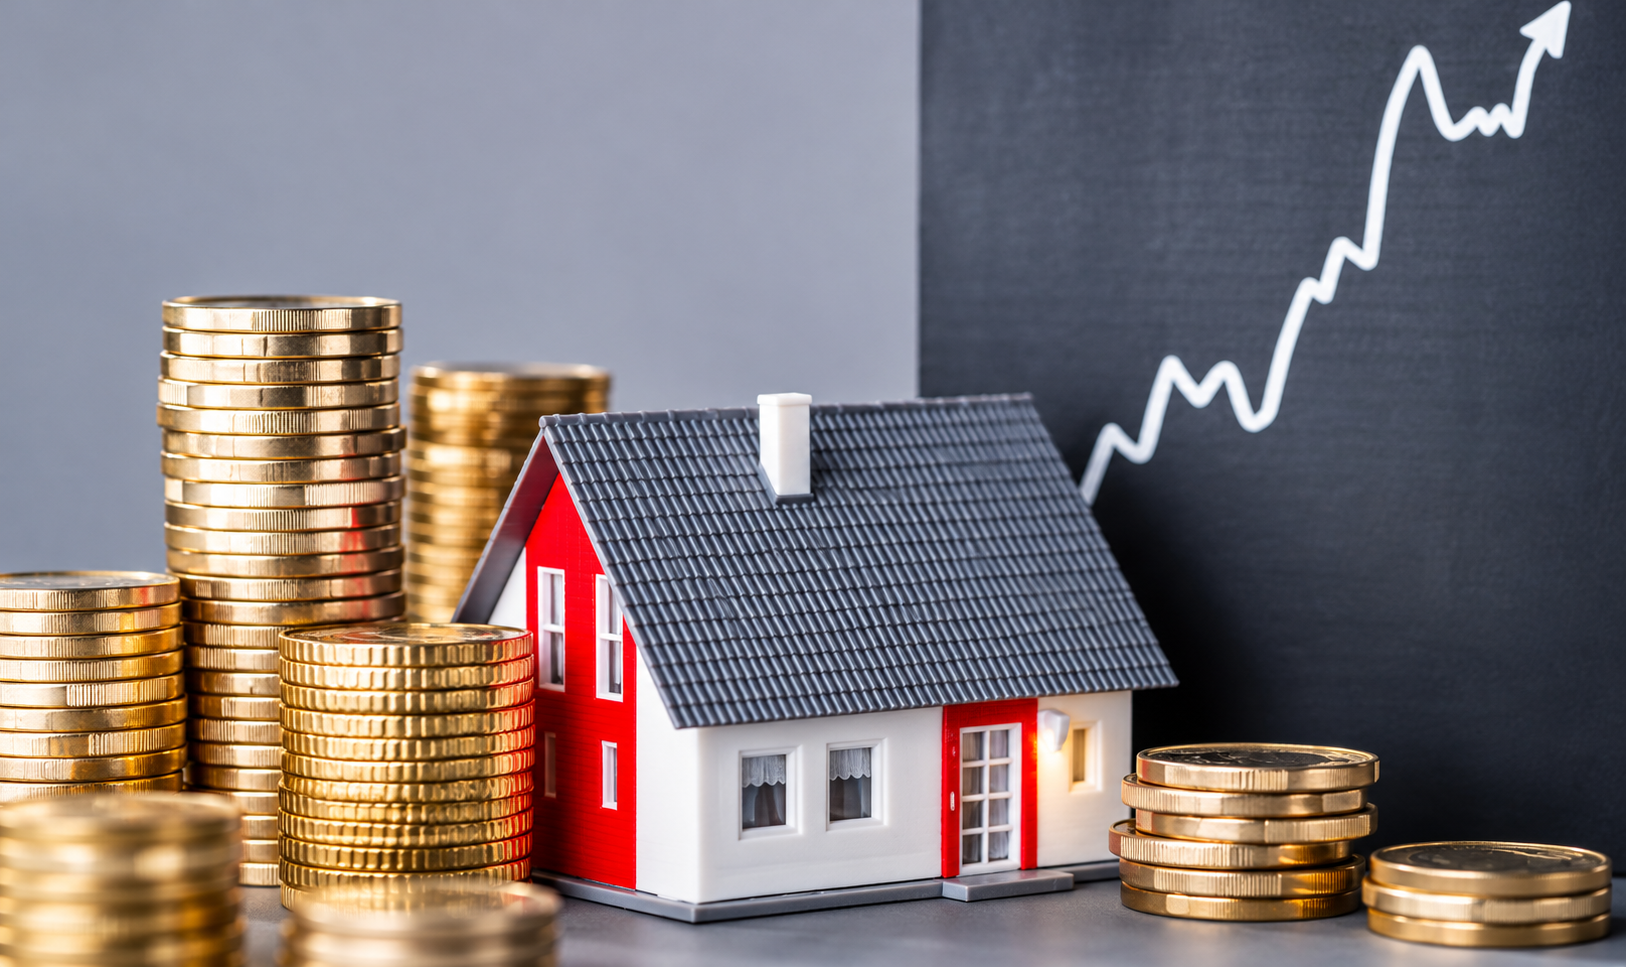

##Project Summary
The main objective of this project is to develop a machine learning system that predicts house prices based on different property features and recommends houses according to user preferences.

The project is divided into three main tasks:

##Task 1: Data Analysis and Preprocessing
The Ames Housing dataset was explored to understand its structure and features. Data cleaning was performed by checking duplicates, handling missing values, removing unnecessary columns, detecting outliers, and analysing skewness. Selected numerical features were treated using the IQR clipping method. This prepared the dataset for further analysis and modelling.

##Task 2(a): House Price Prediction
Machine learning algorithms were developed to predict house prices. Linear Regression and Random Forest Regression were trained and evaluated. The project also explored hyperparameter tuning, log transformation of the target variable, and an ensemble approach combining model predictions.

Model performance was evaluated using:

Mean Absolute Error (MAE)
Root Mean Squared Error (RMSE)
R-squared (R²)
Actual-versus-predicted plots and model comparison charts were used to examine performance.

##Task 2(b): Relationship Between House Features and Price
Correlation analysis was performed to identify which house features are positively related to SalePrice. The analysis highlighted important features such as overall quality, living area, basement area, garage area, and construction year.

##Task 3: House Recommendation System
A recommendation system was developed to find houses based on user requirements. Users can enter a maximum budget, minimum living area, and minimum number of bedrooms. The system filters the dataset and displays matching houses.

##Overall Conclusion
This project demonstrates the use of data analysis, data preprocessing, machine learning, and recommendation techniques in real estate price prediction. It helps understand the factors influencing house prices, estimate property values, and identify houses that match user requirements.

##GitHub Link -
https://github.com/baranisanjay524-debug/House-Price-prediction/upload


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import warnings
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("data.csv")
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
df.drop(['Id'],axis=1,inplace=True)
df

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [ ]:
df.drop(['GarageCars'],axis=1,inplace=True)
df

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [ ]:
df.drop(['TotRmsAbvGrd'],axis=1,inplace=True)
df

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
Street,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [ ]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [ ]:
df.isnull().sum()

,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
Street,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [ ]:
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [ ]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


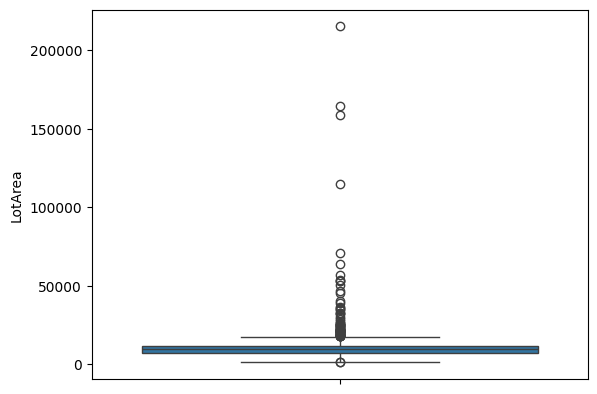

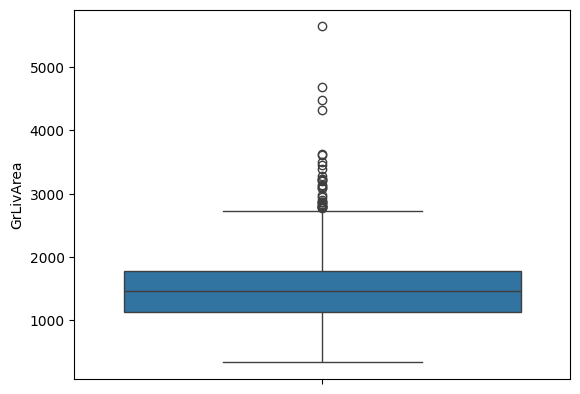

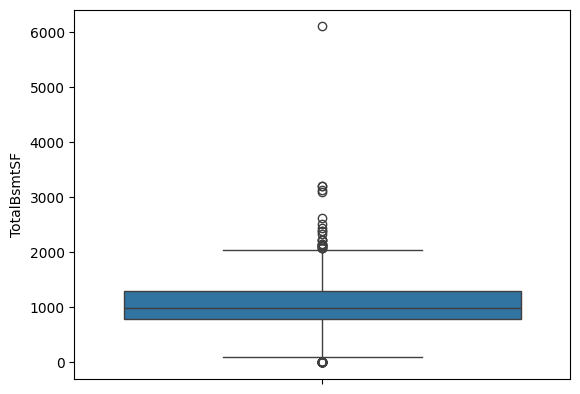

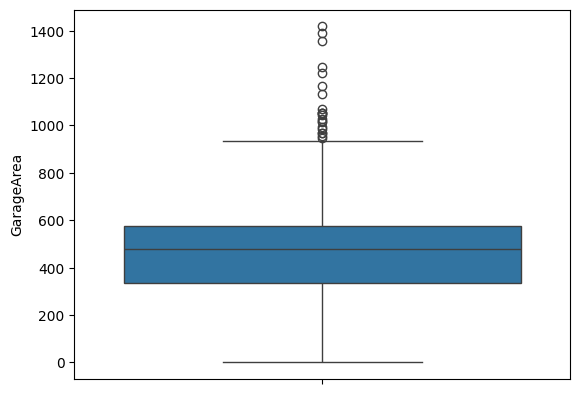

In [ ]:
for i in df[['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']]:
    sns.boxplot(df[i])
    plt.show()

In [ ]:
cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    count = ((df[col] < Q1 - 1.5*IQR) |
             (df[col] > Q3 + 1.5*IQR)).sum()
    print(col, ":", count, "outliers")

LotArea : 69 outliers
GrLivArea : 31 outliers
TotalBsmtSF : 61 outliers
GarageArea : 21 outliers


In [ ]:
cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [ ]:
print(col, ":", count, "outliers")

GarageArea : 21 outliers


In [ ]:
Q1 = df['GarageArea'].quantile(0.25)
Q3 = df['GarageArea'].quantile(0.75)
IQR = Q3 - Q1

count = (
    (df['GarageArea'] < Q1 - 1.5 * IQR) |
    (df['GarageArea'] > Q3 + 1.5 * IQR)
).sum()

print("GarageArea outliers:", count)

GarageArea outliers: 0


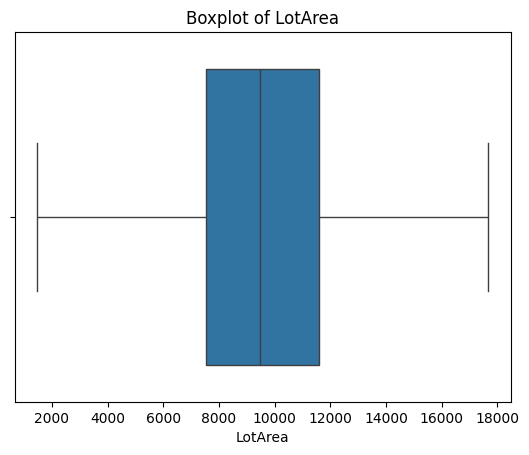

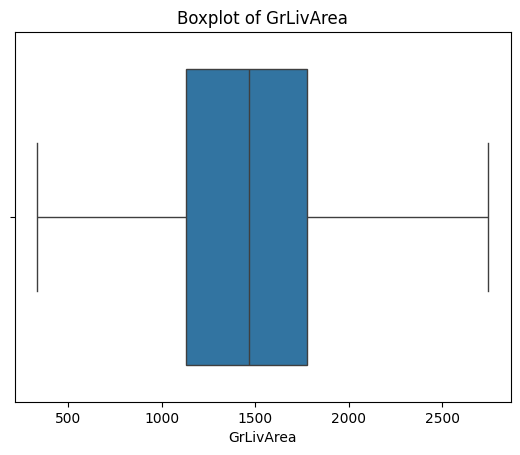

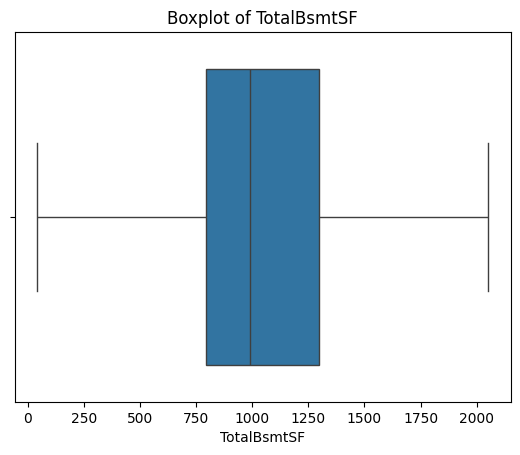

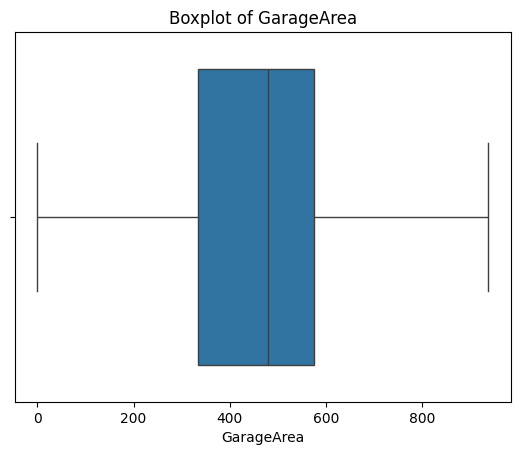

In [ ]:
cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

for col in cols:
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [ ]:
num_cols = df.select_dtypes(include='number').columns.drop(
    'SalePrice', errors='ignore'
)

skewness = df[num_cols].skew().sort_values(ascending=False)

print(skewness)

MiscVal          24.476794
PoolArea         14.828374
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.677616
LotFrontage       2.409147
OpenPorchSF       2.364342
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
MSSubClass        1.407657
1stFlrSF          1.376757
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
HalfBath          0.675897
Fireplaces        0.649565
BsmtFullBath      0.596067
GrLivArea         0.593556
TotalBsmtSF       0.237240
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
LotArea           0.208492
YrSold            0.096269
FullBath          0.036562
GarageArea       -0.069685
YearRemodAdd     -0.503562
YearBuilt        -0.613461
GarageYrBlt      -0.678333
dtype: float64


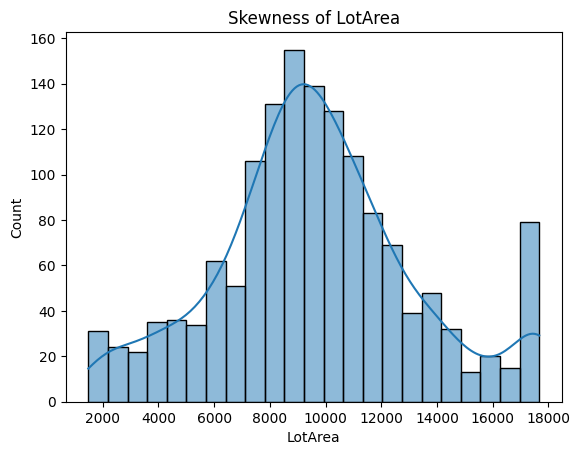

In [ ]:
sns.histplot(df['LotArea'], kde=True)
plt.title('Skewness of LotArea')
plt.show()

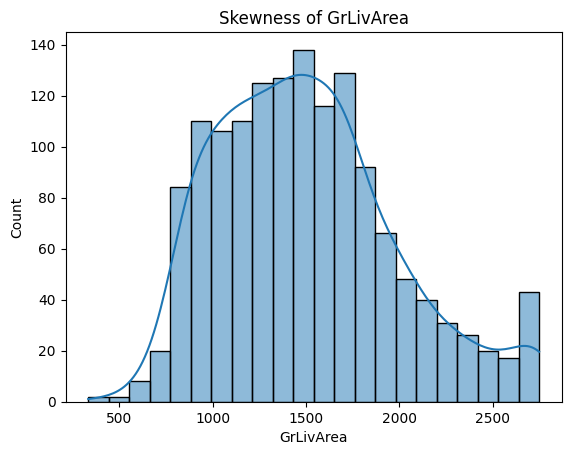

In [ ]:
sns.histplot(df['GrLivArea'], kde=True)
plt.title('Skewness of GrLivArea')
plt.show()

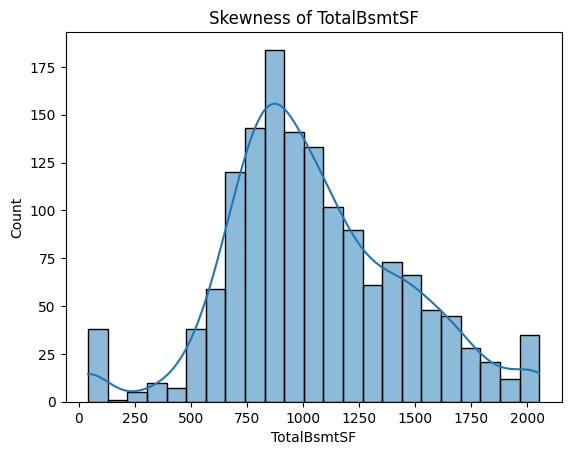

In [ ]:
sns.histplot(df['TotalBsmtSF'], kde=True)
plt.title('Skewness of TotalBsmtSF')
plt.show()

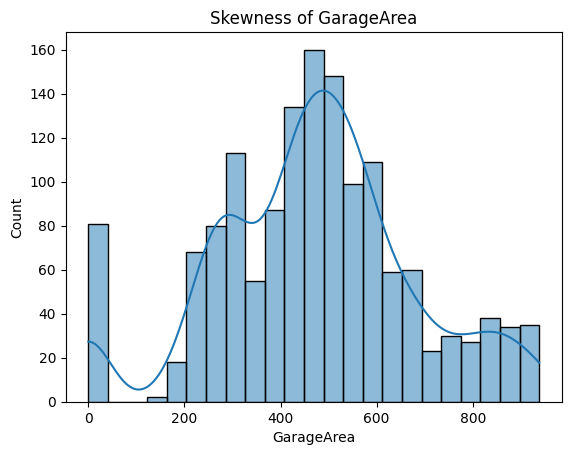

In [ ]:
sns.histplot(df['GarageArea'], kde=True)
plt.title('Skewness of GarageArea')
plt.show()

In [ ]:
df_original = df.copy()

In [ ]:
import numpy as np

cols = ['LotArea','GrLivArea','TotalBsmtSF', 'GarageArea']

for col in cols:
    if df[col].skew() > 1:
        df[col] = np.log1p(df[col])
i
print(df[cols].skew())

LotArea        0.208492
GrLivArea      0.593556
TotalBsmtSF    0.237240
GarageArea    -0.069685
dtype: float64


In [ ]:
cat_cols = df.select_dtypes(include='object').columns

print(cat_cols)

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')


In [ ]:
cat_cols = df.select_dtypes(include='object').columns

df = pd.get_dummies(df, columns=cat_cols, dtype=int)

print("Categorical columns encoded successfully!")

Categorical columns encoded successfully!


In [ ]:
df

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,60,65.0,8450.0,7,5,2003,2003,196.0,706,0,...,0,0,0,1,0,0,0,0,1,0
1,20,80.0,9600.0,6,8,1976,1976,0.0,978,0,...,0,0,0,1,0,0,0,0,1,0
2,60,68.0,11250.0,7,5,2001,2002,162.0,486,0,...,0,0,0,1,0,0,0,0,1,0
3,70,60.0,9550.0,7,5,1915,1970,0.0,216,0,...,0,0,0,1,1,0,0,0,0,0
4,60,84.0,14260.0,8,5,2000,2000,350.0,655,0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,62.0,7917.0,6,5,1999,2000,0.0,0,0,...,0,0,0,1,0,0,0,0,1,0
1456,20,85.0,13175.0,6,6,1978,1988,119.0,790,163,...,0,0,0,1,0,0,0,0,1,0
1457,70,66.0,9042.0,7,9,1941,2006,0.0,275,0,...,0,0,0,1,0,0,0,0,1,0
1458,20,68.0,9717.0,5,6,1950,1996,0.0,49,1029,...,0,0,0,1,0,0,0,0,1,0


In [ ]:
print(df.select_dtypes(include='object').columns)

Index([], dtype='object')


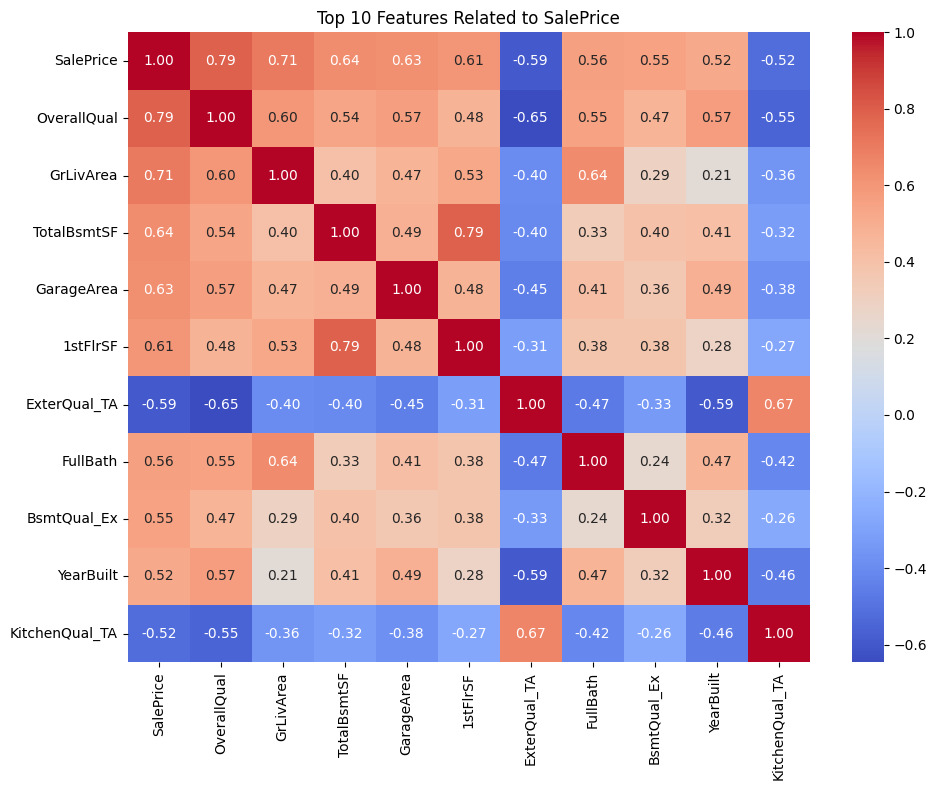

In [ ]:
corr = df.corr(numeric_only=True)

top_features = corr['SalePrice'].drop('SalePrice').abs().nlargest(10).index

selected = ['SalePrice'] + list(top_features)

plt.figure(figsize=(10, 8))

sns.heatmap(df[selected].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')


plt.title('Top 10 Features Related to SalePrice')
plt.tight_layout()
plt.show()

In [ ]:
orr = df.corr(numeric_only=True)
top_features = (
    corr['SalePrice']
    .drop('SalePrice')
    .abs()
    .nlargest(10))

print("Top 10 features related to house price:")
print(top_features)


Top 10 features related to house price:
OverallQual       0.790982
GrLivArea         0.708153
TotalBsmtSF       0.636999
GarageArea        0.630138
1stFlrSF          0.605852
ExterQual_TA      0.589044
FullBath          0.560664
BsmtQual_Ex       0.553105
YearBuilt         0.522897
KitchenQual_TA    0.519298
Name: SalePrice, dtype: float64


In [ ]:
top_features_corr = corr['SalePrice'].loc[top_features.index].sort_values()


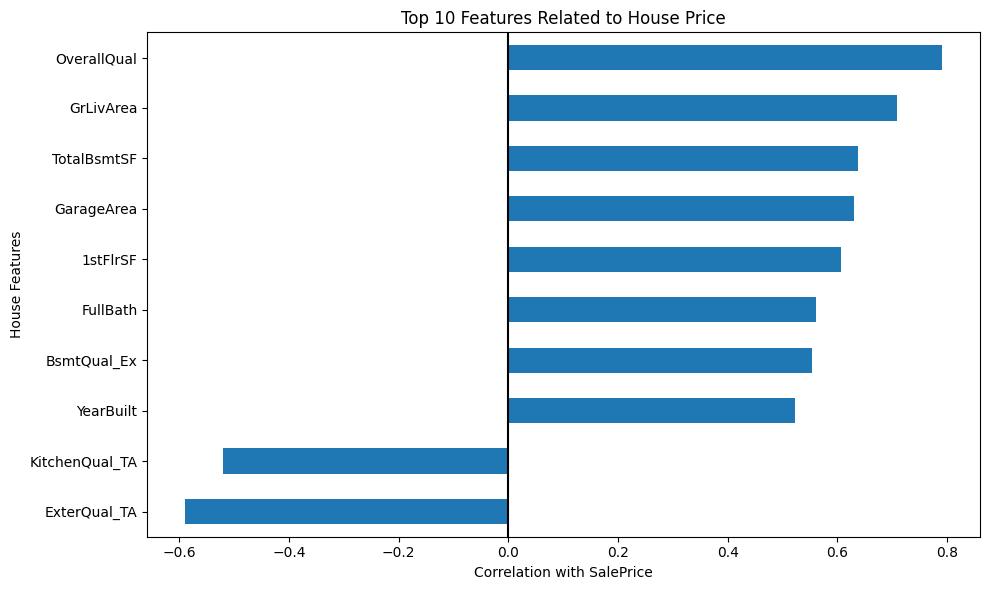

In [ ]:
top_features_corr.plot(kind='barh', figsize=(10, 6))

plt.title('Top 10 Features Related to House Price')
plt.xlabel('Correlation with SalePrice')
plt.ylabel('House Features')
plt.axvline(x=0, color='black')
plt.tight_layout()
plt.show()


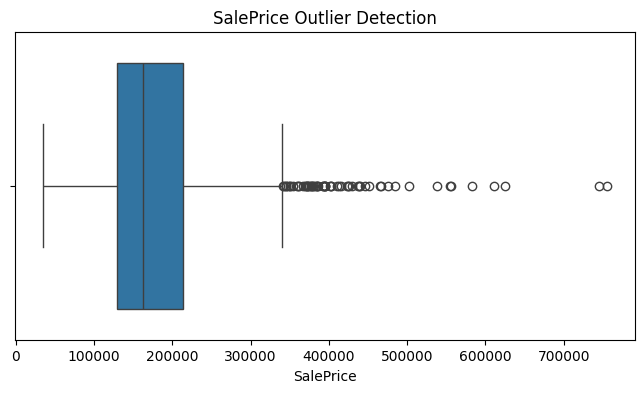

Potential outliers: 61


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["SalePrice"])
plt.title("SalePrice Outlier Detection")
plt.show()


print("Potential outliers:",
      ((df["SalePrice"] < lower) |
       (df["SalePrice"] > upper)).sum())

# Task 1: Data Analysis Report – House Price Prediction

## 1. Introduction

The objective of this project is to analyse house-related data and prepare it for building a machine learning model that predicts house prices. The dataset contains information about house size, quality, location, construction details, and sale prices.

## 2. Dataset Description

The Ames Housing dataset was used for this project.

- **Total records:** 1,460 houses
- **Total columns:** 81
- **Target variable:** SalePrice
- **Features:** House area, overall quality, number of bedrooms, bathrooms, garage area, year built, and other property details.

The dataset was initially explored using `head()`, `tail()`, `describe()`, and `info()` to understand its structure and statistical information.

## 3. Data Cleaning

The following data-cleaning steps were performed:

- Removed unnecessary columns such as `Id`, `GarageCars`, and `TotRmsAbvGrd`.
- Checked for duplicate records.
- Identified missing values in numerical and categorical columns.
- Filled missing numerical values using the median.
- Filled missing categorical values using the mode.
- Checked missing values again after treatment. The output showed no remaining missing values.

## 4. Outlier Detection and Treatment

Boxplots and the Interquartile Range (IQR) method were used to identify potential outliers in the following numerical columns:

| Feature | Outliers detected |
|---|---:|
| LotArea | 69 |
| GrLivArea | 31 |
| TotalBsmtSF | 61 |
| GarageArea | 21 |

The IQR method was used to calculate lower and upper limits. Values outside these limits were treated using the `clip()` method.

This process reduced the effect of extreme values while retaining the records in the dataset.

## 5. Skewness Analysis

Skewness was calculated for numerical features to understand the distribution of the data.

Histograms were plotted for `LotArea`, `GrLivArea`, `TotalBsmtSF`, and `GarageArea` to examine their distributions.

After outlier treatment, the skewness values of these four features were below 1. Therefore, the notebook's conditional log-transformation step did not apply a log transformation to them.

## 6. Conclusion

Task 1 focused on understanding, cleaning, and preparing the Ames Housing dataset. Missing values were handled, unnecessary columns were removed, and potential outliers in selected numerical features were treated using IQR-based clipping.

The dataset was then checked for skewness and prepared for further analysis and machine learning.

These preprocessing steps provide a cleaner dataset for the next stages of the house price prediction project.

**task** 2

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 285)
Testing data: (292, 285)


In [ ]:
from sklearn.model_selection import train_test_split


X = df.drop('SalePrice', axis=1)
y = df['SalePrice']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Training data shape: (1168, 285)
Testing data shape: (292, 285)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

print("Linear Regression Results (After Scaling)")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", mean_squared_error(y_test, lr_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, lr_pred))

Linear Regression Results (After Scaling)
MAE: 18064.71475820172
RMSE: 28645.001896651036
R2 Score: 0.8930246104930588


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = GridSearchCV(
    LinearRegression(),
    {"fit_intercept": [True, False]},
    cv=3,
    scoring="neg_root_mean_squared_error")

model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print("Best Parameters:", model.best_params_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, lr_pred))

Best Parameters: {'fit_intercept': True}
MAE: 18064.71475820172
RMSE: 28645.001896651036
R2 Score: 0.8930246104930588


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = GridSearchCV(
    Ridge(),
    {"alpha": [0.1, 1, 10, 50, 100]},
    cv=3,
    scoring="neg_root_mean_squared_error"
)

model.fit(X_train_scaled, y_train)
pred = model.predict(X_test_scaled)

print("Best Parameters:", model.best_params_)
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
print("R2 Score:", r2_score(y_test, pred))

Best Parameters: {'alpha': 100}
MAE: 18155.077460666227
RMSE: 29818.84155849181
R2 Score: 0.8840775101510951


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Initialize models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(random_state=42)

# Train existing Linear Regression with log-transformed prices
lr_model.fit(X_train_scaled, np.log1p(y_train))
lr_pred_log = lr_model.predict(X_test_scaled)
lr_pred = np.expm1(lr_pred_log)

print("Linear Regression after log transformation")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:", r2_score(y_test, lr_pred))

# Train existing Random Forest with log-transformed prices
rf_model.fit(X_train, np.log1p(y_train))
rf_pred_log = rf_model.predict(X_test)
rf_pred = np.expm1(rf_pred_log)

print("\nRandom Forest after log transformation")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

Linear Regression after log transformation
MAE: 15224.56948022574
RMSE: 24901.09862920273
R2 Score: 0.9191605811549085

Random Forest after log transformation
MAE: 18112.078291200567
RMSE: 30892.25288605656
R2 Score: 0.8755813947675579


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", mean_squared_error(y_test, rf_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, rf_pred))

Random Forest Results
MAE: 17844.223047945205
RMSE: 29183.879519609483
R2 Score: 0.888961851059602


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2, 4]
}

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=5,
    cv=2,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

best_rf = random_search.best_estimator_
rf_tuned_pred = best_rf.predict(X_test)

print("\nTuned Random Forest Results")
print("MAE:", mean_absolute_error(y_test, rf_tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_tuned_pred)))
print("R2 Score:", r2_score(y_test, rf_tuned_pred))


Fitting 2 folds for each of 5 candidates, totalling 10 fits
Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': None}
Best CV MAE: 18520.684703398958

Tuned Random Forest Results
MAE: 18393.597340316075
RMSE: 30283.65524758263
R2 Score: 0.8804353621499027


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 200],
        "max_depth": [15, None],
        "min_samples_leaf": [1, 2]
    },
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

rf_search.fit(X_train, y_train)
rf_pred = rf_search.predict(X_test)

print("Best Parameters:", rf_search.best_params_)
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
MAE: 17844.223047945205
RMSE: 29183.879519609483
R2 Score: 0.888961851059602


In [ ]:
import pandas as pd

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 15 Important Features:")
print(importance.head(15))

Top 15 Important Features:
OverallQual         0.556085
GrLivArea           0.124971
2ndFlrSF            0.036194
TotalBsmtSF         0.032696
BsmtFinSF1          0.030283
1stFlrSF            0.027262
GarageArea          0.019122
LotArea             0.015687
YearBuilt           0.012335
LotFrontage         0.009867
GarageFinish_Unf    0.006870
OpenPorchSF         0.006697
YearRemodAdd        0.006685
GarageYrBlt         0.006346
FullBath            0.006024
dtype: float64


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ensemble_pred = (lr_pred + rf_pred) / 2

ensemble_mae = mean_absolute_error(y_test, ensemble_pred)
ensemble_rmse = np.sqrt(mean_squared_error(y_test, ensemble_pred))
ensemble_r2 = r2_score(y_test, ensemble_pred)

print("Ensemble Model Results")
print("MAE:", ensemble_mae)
print("RMSE:", ensemble_rmse)
print("R2 Score:", ensemble_r2)

print("\n--- Model Comparison ---")

for name, pred in [
    ("Linear Regression", lr_pred),
    ("Random Forest", rf_pred),
    ("Ensemble", ensemble_pred)
]:
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_test, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
    print("R2 Score:", round(r2_score(y_test, pred), 4))

Ensemble Model Results
MAE: 14847.408453501328
RMSE: 25058.507692332816
R2 Score: 0.91813531904571

--- Model Comparison ---

Linear Regression
MAE: 15224.57
RMSE: 24901.1
R2 Score: 0.9192

Random Forest
MAE: 17844.22
RMSE: 29183.88
R2 Score: 0.889

Ensemble
MAE: 14847.41
RMSE: 25058.51
R2 Score: 0.9181


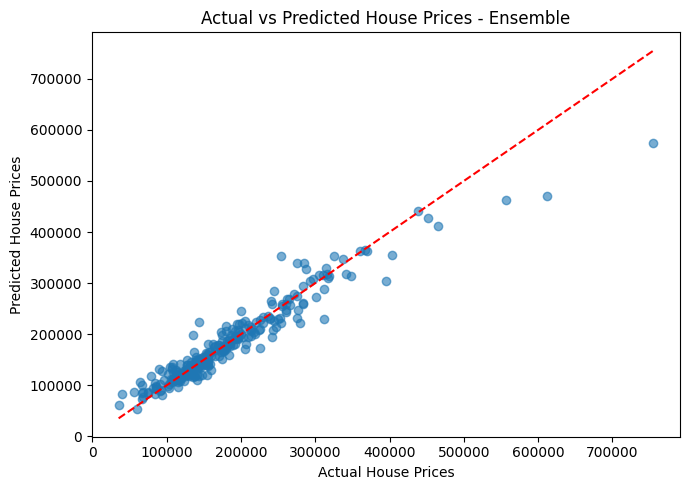

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, ensemble_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices - Ensemble")

low = min(y_test.min(), ensemble_pred.min())
high = max(y_test.max(), ensemble_pred.max())
plt.plot([low, high], [low, high], "r--")

plt.tight_layout()
plt.show()

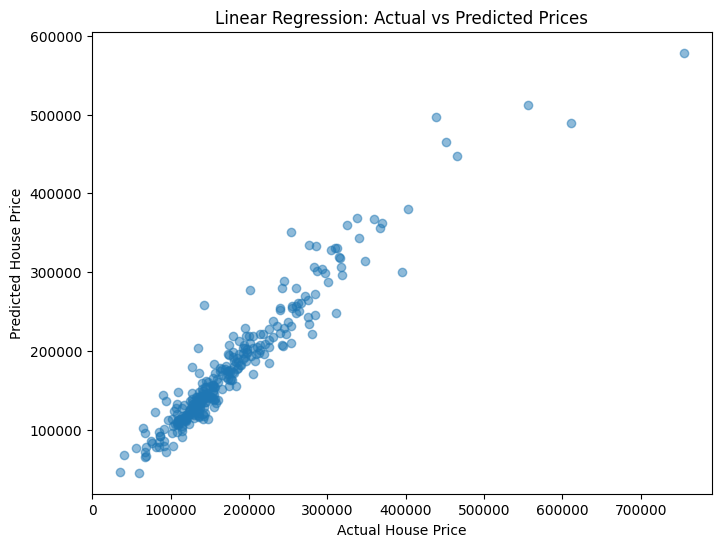

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_pred, alpha=0.5)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Linear Regression: Actual vs Predicted Prices")
plt.show()

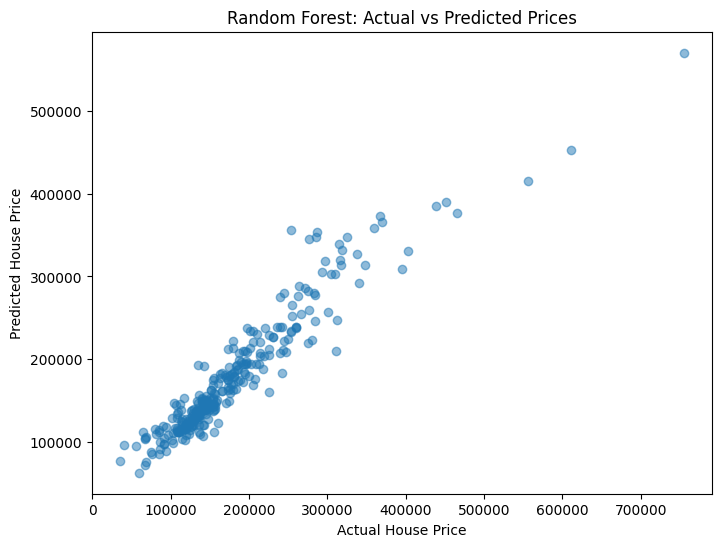

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.5)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Random Forest: Actual vs Predicted Prices")
plt.show()

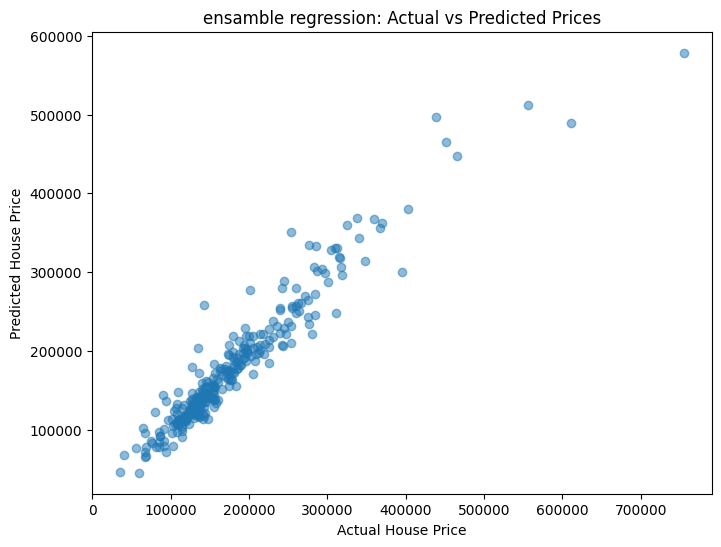

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_pred, alpha=0.5)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("ensamble regression: Actual vs Predicted Prices")
plt.show()

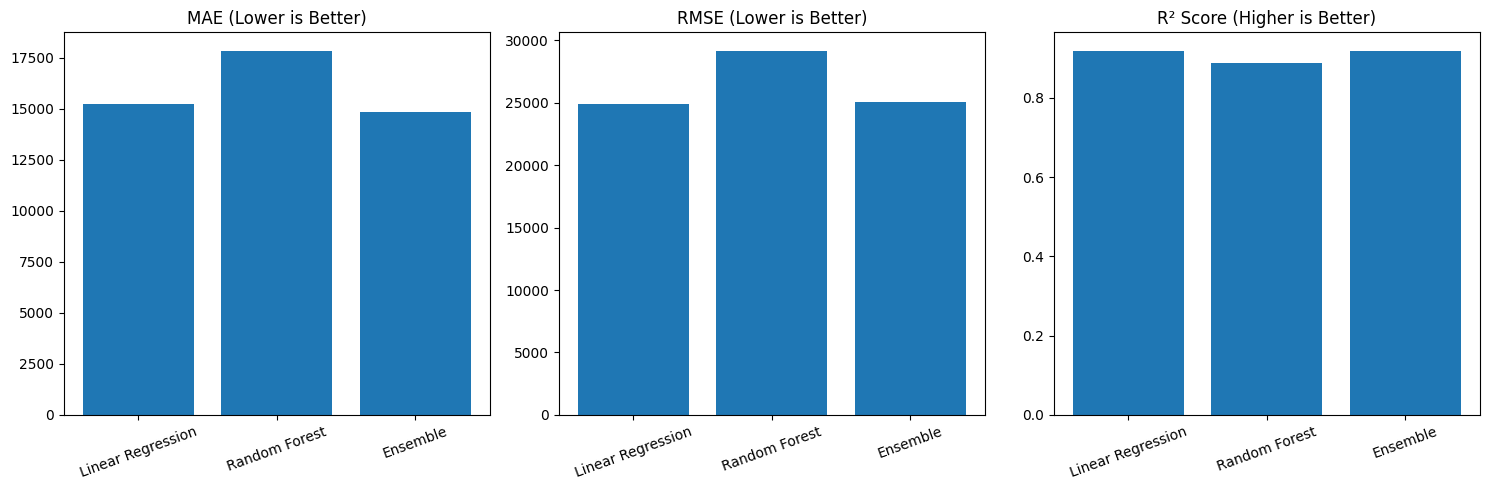

In [ ]:
import matplotlib.pyplot as plt

model_names = ["Linear Regression", "Random Forest", "Ensemble"]

mae_scores = [
    mean_absolute_error(y_test, lr_pred),
    mean_absolute_error(y_test, rf_pred),
    mean_absolute_error(y_test, ensemble_pred)
]

rmse_scores = [
    np.sqrt(mean_squared_error(y_test, lr_pred)),
    np.sqrt(mean_squared_error(y_test, rf_pred)),
    np.sqrt(mean_squared_error(y_test, ensemble_pred))
]

r2_scores = [
    r2_score(y_test, lr_pred),
    r2_score(y_test, rf_pred),
    r2_score(y_test, ensemble_pred)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(model_names, mae_scores)
axes[0].set_title("MAE (Lower is Better)")
axes[1].bar(model_names, rmse_scores)
axes[1].set_title("RMSE (Lower is Better)")
axes[2].bar(model_names, r2_scores)
axes[2].set_title("R² Score (Higher is Better)")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [ ]:
print("Linear Regression:", r2_score(y_test, lr_pred) * 100, "%")
print("Random Forest:", r2_score(y_test, rf_pred) * 100, "%")
print("Ensemble:", r2_score(y_test, ensemble_pred) * 100, "%")

Linear Regression: 91.91605811549086 %
Random Forest: 88.8961851059602 %
Ensemble: 91.813531904571 %


task 2(b) – Relationship Between House Features and House **Price**

Top 10 features positively related to house price:
OverallQual       0.790982
GrLivArea         0.708153
TotalBsmtSF       0.636999
GarageArea        0.630138
1stFlrSF          0.605852
FullBath          0.560664
BsmtQual_Ex       0.553105
YearBuilt         0.522897
YearRemodAdd      0.507101
KitchenQual_Ex    0.504094
Name: SalePrice, dtype: float64


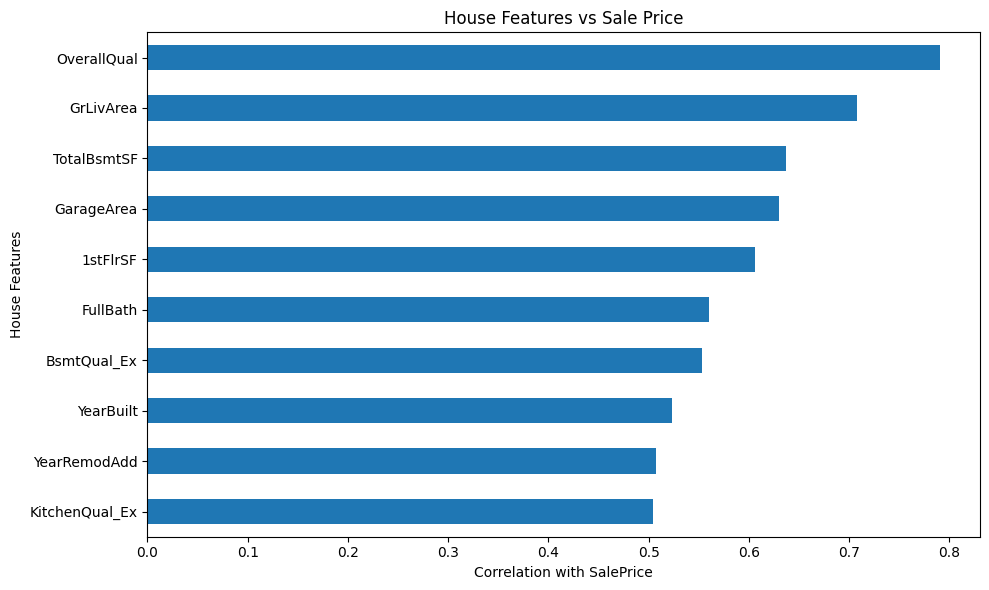

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation = df.corr(numeric_only=True)['SalePrice']
correlation = correlation.drop('SalePrice').sort_values(ascending=False)

print("Top 10 features positively related to house price:")
print(correlation.head(10))

plt.figure(figsize=(10, 6))
correlation.head(10).sort_values().plot(kind='barh')
plt.title("House Features vs Sale Price")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("House Features")
plt.tight_layout()
plt.show()

# Task 3: House Recommendation **System**

In [ ]:
budget = float(input("Enter your maximum budget: "))
min_area = float(input("Enter minimum living area in square feet: "))
min_bedrooms = int(input("Enter minimum number of bedrooms: "))

print("\nCustomer Requirements")
print("Maximum Budget:", budget)
print("Minimum Living Area:", min_area, "sq ft")
print("Minimum Bedrooms:", min_bedrooms)

Enter your maximum budget: 450000
Enter minimum living area in square feet: 150
Enter minimum number of bedrooms: 3

Customer Requirements
Maximum Budget: 450000.0
Minimum Living Area: 150.0 sq ft
Minimum Bedrooms: 3


In [ ]:
matching_houses = df_original[
    (df["SalePrice"] <= budget) &
    (df["GrLivArea"] >= min_area) &
    (df["BedroomAbvGr"] >= min_bedrooms)
]

print("Matching houses based on your requirements:")
display(matching_houses[['SalePrice', 'GrLivArea', 'BedroomAbvGr']].head(10))

Matching houses based on your requirements:


,SalePrice,GrLivArea,BedroomAbvGr
0,208500,1710.0,3
1,181500,1262.0,3
2,223500,1786.0,3
3,140000,1717.0,3
4,250000,2198.0,4
6,307000,1694.0,3
7,200000,2090.0,3
10,129500,1040.0,3
11,345000,2324.0,4
13,279500,1494.0,3


In [ ]:
if len(matching_houses) > 0:
    print("Recommended Houses:")
    print(matching_houses[['SalePrice', 'GrLivArea', 'BedroomAbvGr']].head(10))
else:
    print("No houses found. Try changing your requirements.")


Recommended Houses:
    SalePrice  GrLivArea  BedroomAbvGr
4      250000     2198.0             4
11     345000     2324.0             4
20     325300     2376.0             4
33     165500     1700.0             4
35     309000     2452.0             4
65     317000     2473.0             4
78     136500     1768.0             4
80     193500     2142.0             4
85     260000     2417.0             4
93     133900     2291.0             4


In [ ]:
print("Total houses available:", len(df_original))
print("Recommended houses found:", len(matching_houses))

Total houses available: 1460
Recommended houses found: 242


## Conclusion

The House Price Prediction project successfully demonstrates the application of data analysis and machine learning techniques to predict house prices using the Ames Housing dataset. Data preprocessing techniques, including handling missing values, removing unnecessary columns, treating outliers, and encoding categorical variables, were performed to improve data quality and prepare the dataset for model training.

Three machine learning approaches were evaluated: Linear Regression with log-transformed target values, Random Forest Regression, and an Ensemble Model. Their performance was compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

### Model Evaluation Results

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 15,224.57 | 24,901.10 | 0.9192 |
| Random Forest | 17,844.22 | 29,183.88 | 0.8890 |
| Ensemble Model | 14,847.41 | 25,058.51 | 0.9181 |

Based on the evaluation metrics, the **Ensemble Model performed best in terms of MAE**, achieving the lowest value of 14,847.41. This indicates that it produces the smallest average absolute difference between actual and predicted house prices.

However, **Linear Regression achieved the best RMSE of 24,901.10 and the highest R² score of 0.9192 (91.92%)**. This demonstrates that Linear Regression provides slightly better overall predictive performance in terms of reducing larger prediction errors and explaining the variation in house prices. Random Forest showed comparatively lower performance across all three evaluation metrics.

### Most Suitable Model for Future House Price Predictions

Based on the evaluation results, **Linear Regression with log-transformed target values is selected as the most suitable primary model for future house price predictions**.

The main reasons for selecting Linear Regression are:

1. **Lowest RMSE:** It achieved the lowest RMSE of 24,901.10, indicating better control over larger prediction errors.
2. **Highest R² Score:** Its R² score of 0.9192 indicates that it explains approximately 91.92% of the variation in house prices.
3. **Competitive MAE:** Its MAE of 15,224.57 is close to the Ensemble Model's MAE, showing that its average prediction error is also relatively low.
4. **Reliable Predictive Performance:** Its strong performance across the evaluation metrics makes it a suitable choice for estimating house prices.

The Ensemble Model is also a strong alternative, particularly when minimizing average absolute prediction error is the main priority. It achieved the lowest MAE of 14,847.41, making it useful when reducing the average difference between actual and predicted prices is important.

### Important Features Affecting House Prices

Feature importance analysis from the Random Forest model identified Overall Quality, Ground Living Area, and Second Floor Area as important factors influencing house prices. These features provide useful insights into the characteristics that contribute significantly to property values.

### Future Improvements

The project could be improved further by applying cross-validation, exploring additional machine learning algorithms, performing more advanced feature engineering, collecting additional housing data, and testing the models on newer datasets. These improvements could help increase prediction accuracy and improve reliability when applying the system to real-world housing markets.

Overall, this project demonstrates that machine learning can support reliable house price estimation and property recommendations. **Linear Regression is recommended as the preferred model for future predictions based on its superior RMSE and R² performance, while the Ensemble Model is recommended as an alternative when minimizing MAE is the main objective.**